# First session (GUIDE.md section 13)

Baldick's SOC-based ESS market design vs. the best-possible conventional bid/offer
curve, under uncertainty, on real RTS-GMLC Area 1 data. This notebook follows
GUIDE.md's own prescribed order:

1. Load both CSVs, plot `wind_DA` vs `wind_RT` for one week -- confirm the error structure.
2. Pick three representative days (high wind, low wind, high load).
3. Build the merit-order clearing with no battery and check test 9.1.
4. Only then: one representative day, full pipeline -- Baldick benchmark, DP value
   function, curve construction, conventional clearing, and the validation checks from
   section 9.
5. A small run of the section 8 comparison loop across forecast quality `k`.

All the validation claims here are also pinned down as regression tests in
`tests/test_equivalence.py` -- run `pytest` before trusting anything downstream of this
notebook, exactly as GUIDE.md section 9 insists.


In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, baldick, dp, errors, clearing, compare
from src.curves import build_curve

pd.set_option("display.width", 120)


## 1. Load the data and confirm the error structure

In [2]:
units = data.load_units()
ts = data.load_timeseries()
units

,Block,PMax_MW,MC_eur_MWh,n_units
0,NUCLEAR_Nuclear,400.0,8.103500,1.0
1,STEAM_Coal,1119.0,25.583014,8.0
2,CC_NG,710.0,28.141529,2.0
3,CT_NG,385.0,50.353382,7.0
4,CT_Oil,80.0,143.613449,4.0
5,STEAM_Oil,24.0,179.458596,2.0


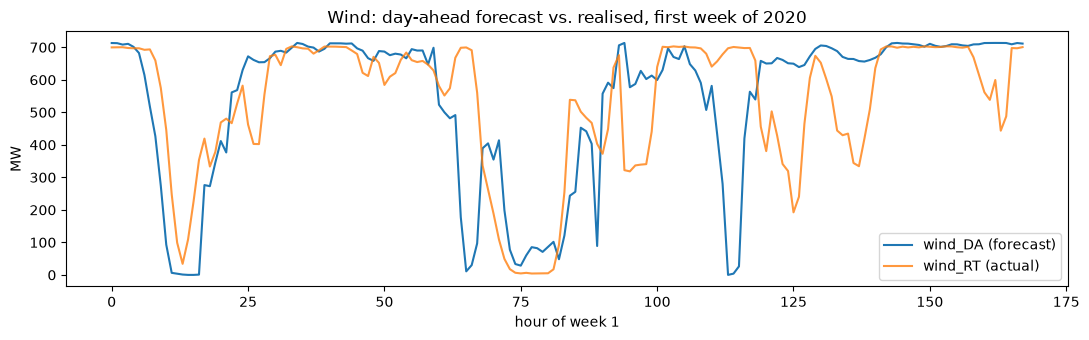

In [3]:
week = ts.iloc[:24*7]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(week["wind_DA"].to_numpy(), label="wind_DA (forecast)")
ax.plot(week["wind_RT"].to_numpy(), label="wind_RT (actual)", alpha=0.8)
ax.set_xlabel("hour of week 1")
ax.set_ylabel("MW")
ax.set_title("Wind: day-ahead forecast vs. realised, first week of 2020")
ax.legend()
fig.tight_layout()
plt.show()

In [4]:
wind_err = errors.error_series(ts["wind_DA"].to_numpy(), ts["wind_RT"].to_numpy())
pv_err = errors.error_series(ts["pv_DA"].to_numpy(), ts["pv_RT"].to_numpy())
wind_ar1 = errors.fit_ar1(wind_err)
pv_ar1 = errors.fit_ar1(pv_err)

print(f"wind error: std={wind_err.std():.1f} MW, AR(1) rho={wind_ar1.rho:.3f}  (GUIDE.md quotes ~184 MW, rho~0.87)")
print(f"pv error:   std={pv_err.std():.1f} MW, AR(1) rho={pv_ar1.rho:.3f}  (GUIDE.md quotes rho~0.73)")
print(f"wind/DA-RT correlation: {np.corrcoef(ts['wind_DA'], ts['wind_RT'])[0,1]:.3f}  (GUIDE.md quotes 0.749)")
print(f"load DA/RT correlation: {np.corrcoef(ts['load_DA'], ts['load_RT'])[0,1]:.3f}  (GUIDE.md: 1.000, a fixed scaling, not uncertainty)")

wind error: std=183.8 MW, AR(1) rho=0.867  (GUIDE.md quotes ~184 MW, rho~0.87)
pv error:   std=30.7 MW, AR(1) rho=0.730  (GUIDE.md quotes rho~0.73)
wind/DA-RT correlation: 0.749  (GUIDE.md quotes 0.749)
load DA/RT correlation: 1.000  (GUIDE.md: 1.000, a fixed scaling, not uncertainty)


Matches GUIDE.md's quoted reference statistics closely. Confirms: wind is the real
uncertainty source, load is a near-deterministic rescaling (used as `load_RT`
throughout, never perturbed), and PV's error is smaller and AR(1)-plausible.

## 2. Three representative days

In [11]:
week_number = 2
week_chosen =  ts.iloc[1+(week_number*24*7):1+(24*7*week_number)+24*7]
days = data.pick_representative_days(week_chosen)
days

{'high_wind': (np.int64(1), np.int64(17)),
 'low_wind': (np.int64(1), np.int64(19)),
 'high_load': (np.int64(1), np.int64(15))}

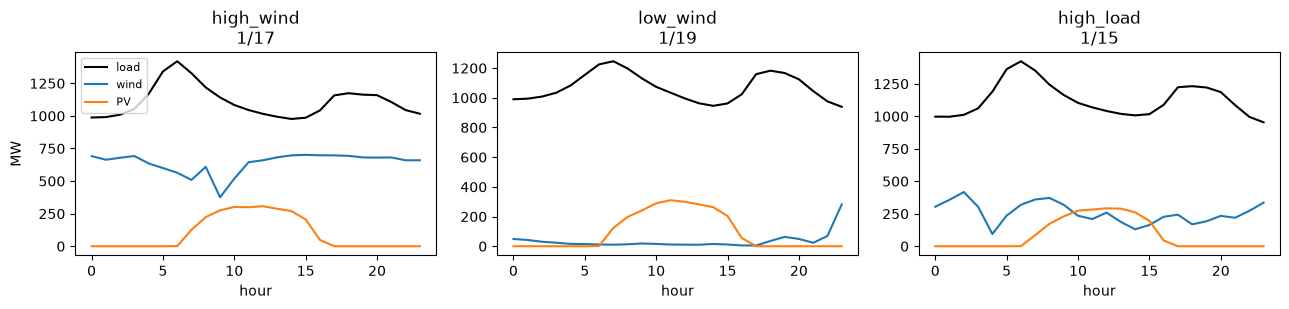

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=False)
for ax, (label, (m, d)) in zip(axes, days.items()):
    day = data.day_slice(ts, m, d)
    ax.plot(day["load_RT"], label="load", color="black")
    ax.plot(day["wind_RT"], label="wind", color="tab:blue")
    ax.plot(day["pv_RT"], label="PV", color="tab:orange")
    ax.set_title(f"{label}\n{int(m)}/{int(d)}")
    ax.set_xlabel("hour")
axes[0].set_ylabel("MW")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Merit-order sanity (GUIDE.md section 9.1) -- no battery, no uncertainty

In [7]:
m, d = days["high_load"]
day = data.day_slice(ts, m, d)
demand = day["load_RT"].to_numpy()
wind = day["wind_RT"].to_numpy()
pv = day["pv_RT"].to_numpy()

zero_storage = baldick.StorageSpec(alpha=0.95, beta=0.95, s_min=0.0, s_max=0.0, s0=0.0, c_max=0.0, d_max=0.0)
no_battery = baldick.solve_baldick(units, demand, wind, pv, zero_storage, dt=1.0)

net_load = demand - wind - pv
reference_price = baldick.merit_order_price(units, net_load)

print("max |LP price - independent merit-order price| =", np.max(np.abs(no_battery.price - reference_price)))
print("\nallowed marginal costs:", sorted(units['MC_eur_MWh'].round(3).tolist()))
print("prices seen this day:  ", sorted(set(no_battery.price.round(3))))

max |LP price - independent merit-order price| = 0.0

allowed marginal costs: [8.104, 25.583, 28.142, 50.353, 143.613, 179.459]
prices seen this day:   [np.float64(25.583), np.float64(28.142)]


Exact match (to solver tolerance) -- test 9.1 passes. Every hourly price sits at one
of `units.csv`'s six block marginal costs, as required.

## 4. One representative day, full pipeline

GUIDE.md's suggested battery (100 MW / 400 MWh) is comparable in size to several
individual thermal blocks (`CT_Oil`=80 MW, `STEAM_Oil`=24 MW). As documented in
`tests/test_equivalence.py`, a storage that size has a real *price-impact* effect that
keeps the conventional-market reconstruction from converging as tightly as a smaller,
price-taking storage does. We use a smaller battery here (20 MW / 80 MWh) so the plots
below show a clean, well-converged equivalence at k=0; the 100 MW case is worth
revisiting explicitly as a price-impact finding in its own right.

In [8]:
storage = baldick.StorageSpec(
    alpha=0.95, beta=0.95, s_min=0.0, s_max=80.0, s0=40.0,
    c_max=20.0, d_max=20.0, epsilon=0.5, zeta=0.5, b_slope=8.5,
)

bald = baldick.solve_baldick(units, demand, wind, pv, storage, dt=1.0)
bald.to_frame()

,Thermal (MW),Wind (MW),PV (MW),Charge (MW),Discharge (MW),SOC (MWh),Price (EUR/MWh),mu (EUR/MWh)
Interval,,,,,,,,
1,1519.72,38.64,0.00,0.0,0.0,40.000000,28.141529,26.259453
2,1479.35,10.34,0.00,0.0,0.0,40.000000,25.583014,26.259453
3,1445.26,4.90,0.00,0.0,0.0,40.000000,25.583014,26.259453
4,1428.77,5.12,0.00,0.0,0.0,40.000000,25.583014,26.259453
5,1436.36,6.68,0.01,0.0,0.0,40.000000,25.583014,26.259453
6,1438.71,9.78,66.17,0.0,0.0,40.000000,25.583014,26.259453
7,1490.16,7.44,150.61,0.0,0.0,40.000000,25.583014,26.259453
8,1551.91,6.85,210.78,0.0,0.0,40.000000,28.141529,26.259453
9,1632.53,11.80,240.32,0.0,0.0,40.000000,28.141529,26.259453


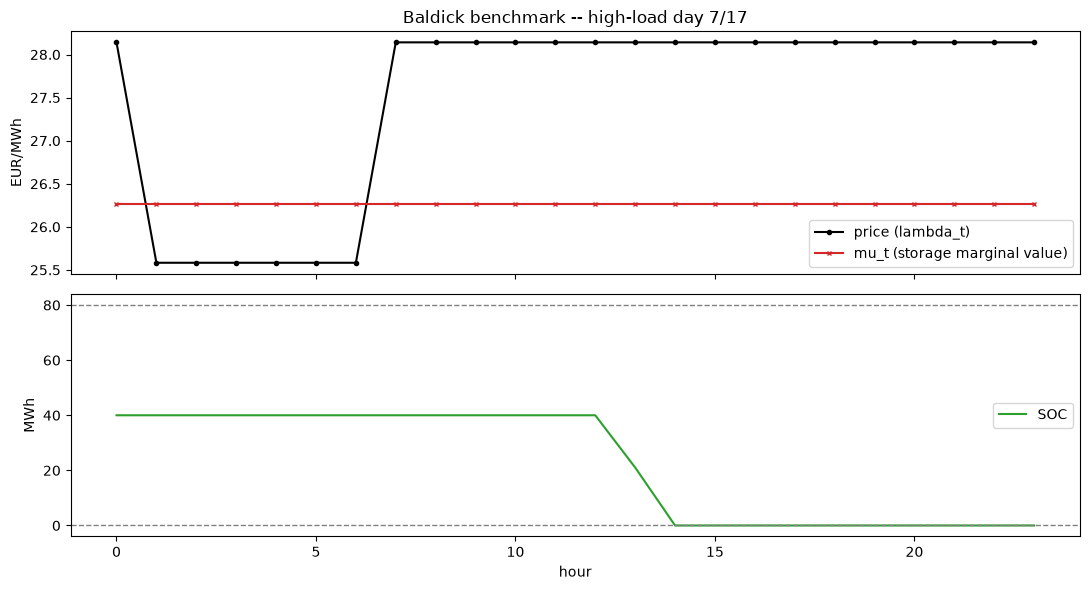

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(bald.price, label="price (lambda_t)", color="black", marker="o", ms=3)
axes[0].plot(bald.mu, label="mu_t (storage marginal value)", color="tab:red", marker="x", ms=3)
axes[0].set_ylabel("EUR/MWh")
axes[0].legend()
axes[0].set_title(f"Baldick benchmark -- high-load day {int(m)}/{int(d)}")

axes[1].plot(bald.soc, label="SOC", color="tab:green")
axes[1].axhline(storage.s_max, color="grey", ls="--", lw=1)
axes[1].axhline(storage.s_min, color="grey", ls="--", lw=1)
axes[1].set_ylabel("MWh")
axes[1].set_xlabel("hour")
axes[1].legend()
fig.tight_layout()
plt.show()

### 4a. KKT pricing identity (exact, GUIDE.md section 9.2)

In [10]:
interior_d = (bald.discharge > 1e-6) & (bald.discharge < storage.d_max - 1e-6)
interior_c = (bald.charge > 1e-6) & (bald.charge < storage.c_max - 1e-6)

check = pd.DataFrame({
    "price": bald.price,
    "mu": bald.mu,
    "mu/beta+zeta (discharge offer)": bald.mu / storage.beta + storage.zeta,
    "alpha*mu-epsilon (charge bid)": storage.alpha * bald.mu - storage.epsilon,
    "interior discharge": interior_d,
    "interior charge": interior_c,
}, index=pd.RangeIndex(1, len(bald.price) + 1, name="Interval"))
check.round(4)

,price,mu,mu/beta+zeta (discharge offer),alpha*mu-epsilon (charge bid),interior discharge,interior charge
Interval,,,,,,
1,28.1415,26.2595,28.1415,24.4465,False,False
2,25.5830,26.2595,28.1415,24.4465,False,False
3,25.5830,26.2595,28.1415,24.4465,False,False
4,25.5830,26.2595,28.1415,24.4465,False,False
5,25.5830,26.2595,28.1415,24.4465,False,False
6,25.5830,26.2595,28.1415,24.4465,False,False
7,25.5830,26.2595,28.1415,24.4465,False,False
8,28.1415,26.2595,28.1415,24.4465,False,False
9,28.1415,26.2595,28.1415,24.4465,False,False


At every interior discharge interval, `price` equals `mu/beta+zeta`; at every interior
charge interval, `price` equals `alpha*mu-epsilon` -- exactly `curves.py`'s block-pricing
formulas, derived directly from the LP's own KKT conditions. This is the algebraic
content of "the conventional curve that reproduces Baldick's dispatch always exists."


### 4b. DP value function, curve construction, and the conventional-market reconstruction

In [11]:
DELTA = 4.0
vf = dp.solve_value_function(storage, bald.price, DELTA)
traj = dp.simulate_policy(vf, storage)

print("V_t concave at every t:", all(dp.is_concave(vf.V[t]) for t in range(24)))

disc_curve = [build_curve(vf, t, storage, traj[t])[0] for t in range(24)]
chg_curve = [build_curve(vf, t, storage, traj[t])[1] for t in range(24)]

conv = clearing.clear_conventional(units, demand, wind, pv, storage, disc_curve, chg_curve, dt=1.0)
conv.to_frame()

V_t concave at every t: True


,Thermal (MW),Wind (MW),PV (MW),Discharge (MW),Charge (MW),SOC (MWh),SOC within limits,Price (EUR/MWh)
Interval,,,,,,,,
1,1519.00,38.64,0.00,0.72,0.0,39.242105,True,28.141529
2,1479.35,10.34,0.00,0.00,0.0,39.242105,True,25.583014
3,1445.26,4.90,0.00,0.00,0.0,39.242105,True,25.583014
4,1428.77,5.12,0.00,0.00,0.0,39.242105,True,25.583014
5,1436.36,6.68,0.01,0.00,0.0,39.242105,True,25.583014
6,1438.71,9.78,66.17,0.00,0.0,39.242105,True,25.583014
7,1490.16,7.44,150.61,0.00,0.0,39.242105,True,25.583014
8,1551.91,6.85,210.78,0.00,0.0,39.242105,True,28.141529
9,1632.53,11.80,240.32,0.00,0.0,39.242105,True,28.141529


In [12]:
bald_cost = bald.generation_cost + bald.degradation_cost
conv_cost = conv.true_cost(units, storage)
print(f"Baldick true cost:      {bald_cost:,.2f} EUR")
print(f"Conventional true cost: {conv_cost:,.2f} EUR")
print(f"Gap:                    {conv_cost - bald_cost:,.2f} EUR ({100*(conv_cost-bald_cost)/bald_cost:.2f}% of cost)")
print(f"\nSimultaneous charge+discharge (Baldick):     {bool(np.any((bald.charge>1e-6)&(bald.discharge>1e-6)))}")
print(f"Simultaneous charge+discharge (conventional): {bool(np.any((conv.charge>1e-6)&(conv.discharge>1e-6)))}")
print(f"SOC always within limits (conventional):      {bool(conv.soc_within_bounds.all())}")

Baldick true cost:      937,577.89 EUR
Conventional true cost: 938,293.25 EUR
Gap:                    715.36 EUR (0.08% of cost)

Simultaneous charge+discharge (Baldick):     False
Simultaneous charge+discharge (conventional): False
SOC always within limits (conventional):      True


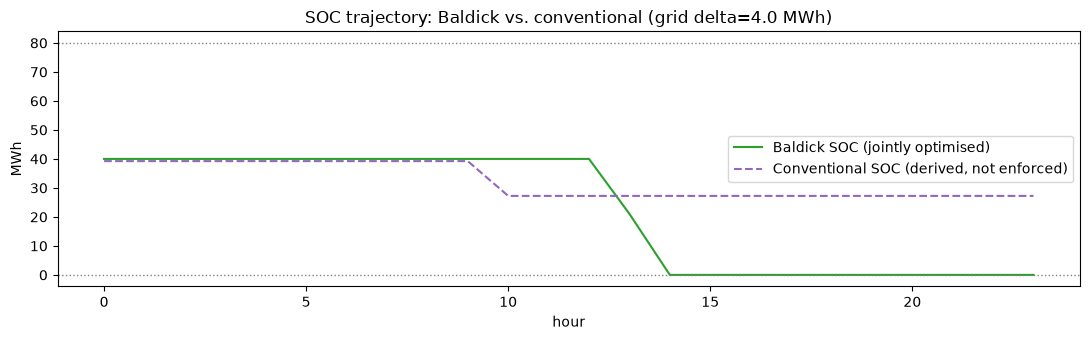

In [13]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(bald.soc, label="Baldick SOC (jointly optimised)", color="tab:green")
ax.plot(conv.soc, label="Conventional SOC (derived, not enforced)", color="tab:purple", ls="--")
ax.axhline(storage.s_max, color="grey", ls=":", lw=1)
ax.axhline(storage.s_min, color="grey", ls=":", lw=1)
ax.set_ylabel("MWh")
ax.set_xlabel("hour")
ax.set_title(f"SOC trajectory: Baldick vs. conventional (grid delta={DELTA} MWh)")
ax.legend()
fig.tight_layout()
plt.show()

At this grid resolution the two trajectories track closely -- the residual gap is the
SOC-grid discretisation error discussed in `dp.py` and `tests/test_equivalence.py`
(finer grids reduce it, but not perfectly monotonically; see the convergence test).

## 5. A small run of the comparison loop (GUIDE.md section 8)

In [14]:
wind_da = day["wind_DA"].to_numpy()
pv_da = day["pv_DA"].to_numpy()

rng = np.random.default_rng(0)
results = compare.run_comparison(
    units, demand, wind_da, pv_da, wind_ar1, pv_ar1, storage,
    delta_grid=DELTA, k_values=(0.0, 0.5, 1.0, 2.0), bias=0.0, n_scenarios=15, rng=rng,
)
summary = compare.summarize(results)
summary

,k,bias,mean,std,min,max,count
0,0.0,0.0,1406.980118,0.000000,1406.980118,1406.980118,15
1,0.5,0.0,191.169819,1043.585157,-1832.964894,1406.980118,15
2,1.0,0.0,-425.814033,1123.482899,-2299.293448,1151.538772,15
3,2.0,0.0,-131.662009,796.783941,-1481.977503,866.081833,15


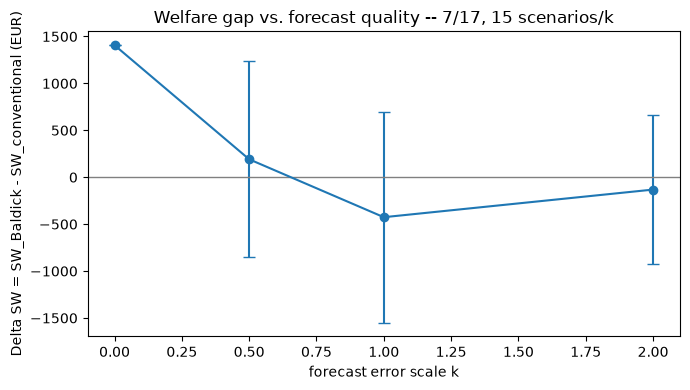

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(summary["k"], summary["mean"], yerr=summary["std"], marker="o", capsize=4)
ax.axhline(0, color="grey", lw=1)
ax.set_xlabel("forecast error scale k")
ax.set_ylabel("Delta SW = SW_Baldick - SW_conventional (EUR)")
ax.set_title(f"Welfare gap vs. forecast quality -- {int(m)}/{int(d)}, {results['scenario'].nunique()} scenarios/k")
fig.tight_layout()
plt.show()

**Reading this plot**: at `k=0` the gap should sit near the grid-discretisation floor
established above (not exactly zero -- see the section-4b caveat and
`tests/test_equivalence.py` for the tight-tolerance version of this same check), then
grow with `k` as GUIDE.md section 1 predicts. Only 15 scenarios and one day are used
here for speed; GUIDE.md section 7.6 suggests 20-50 scenarios, and the full study should
run this across many days, forecast-quality settings, and a grid sensitivity sweep
(section 9.4) before drawing conclusions.